# Graphs in pyAgrum

| | | |
|-|-|-|
|[ ![Creative Commons License](images/cc4.png)](http://creativecommons.org/licenses/by-nc/4.0/) |[ ![aGrUM](images/logoAgrum.png)](https://pyagrum.gitlab.io) |[ ![interactive online version](images/atbinder.svg)](https://mybinder.org/v2/gl/agrumery%2FaGrUM/forBinder?urlpath=%2Fdoc%2Ftree%2Fwrappers%2Fpyagrum%2Fdoc%2Fsphinx%2Fnotebooks%2F03-Tutorial_graphs.ipynb)

pyAgrum provides several kinds of graphs: directed, undirected, mixed (arcs and edges), and graphs whose edges carry a mark at each end. The algorithms on these graphs are gathered in the module `pyagrum.graph`, one function per algorithm whatever the kind of graph.

Below, the essential graph of a Bayesian network: its compelled arcs, and its reversible arcs drawn as edges.

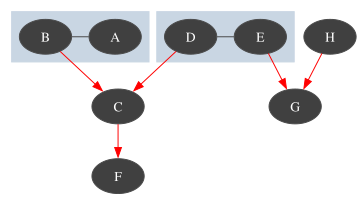

In [1]:
import pyagrum as gum
import pyagrum.graph as gg
import pyagrum.lib.notebook as gnb

gnb.show(gum.EssentialGraph(gum.fastBN("A->B->C<-D<-E->G<-H;C->F")))

## The kinds of graphs

The `fast*` functions build a graph from a string: `A->B` is an arc, `A-B` an edge, and in a marked graph, the marks are `-` (tail), `>`/`<` (arrowhead) and `o` (circle).

A name may be written between single quotes, as in every *fast* syntax: `'Visit Asia'->X` (a doubled quote stands for a quote). Without quotes, a node name contains neither space, `<` nor `>`.

In [2]:
dig = gum.fastDiGraph("A->B->C->A;C->D")  # a directed graph (cycles allowed)
dag = gum.fastDAG("A->B->C;D->C;C->E")  # a directed acyclic graph
ug = gum.fastUndiGraph("A-B-C-D-A;A-C")  # an undirected graph
mg = gum.fastMixedGraph("A->B-C-A")  # a mixed graph (arcs and edges)
pdag = gum.fastPDAG("A->B-C;C-D")  # a mixed graph without directed cycle
cg = gum.fastChainGraph("A->B-C<-D")  # a mixed graph without partially directed cycle
gnb.sideBySide(dig, dag, ug, mg, pdag, cg, captions=["DiGraph", "DAG", "UndiGraph", "MixedGraph", "PDAG", "ChainGraph"])

<!-- 0 --> 0 (0) A <!-- 1 --> 1 (1) B <!-- 0->1 --> 0->1 <!-- 2 --> 2 (2) C <!-- 1->2 --> 1->2 <!-- 2->0 --> 2->0 <!-- 3 --> 3 (3) D <!-- 2->3 --> 2->3 DiGraph,<!-- 0 --> 0 (0) A <!-- 1 --> 1 (1) B <!-- 0->1 --> 0->1 <!-- 2 --> 2 (2) C <!-- 1->2 --> 1->2 <!-- 4 --> 4 (4) E <!-- 2->4 --> 2->4 <!-- 3 --> 3 (3) D <!-- 3->2 --> 3->2 DAG,<!-- 0 --> 0 (0) A <!-- 1 --> 1 (1) B <!-- 0--1 --> 0--1 <!-- 2 --> 2 (2) C <!-- 0--2 --> 0--2 <!-- 3 --> 3 (3) D <!-- 0--3 --> 0--3 <!-- 1--2 --> 1--2 <!-- 2--3 --> 2--3 UndiGraph,<!-- 0 --> 0 (0) A <!-- 1 --> 1 (1) B <!-- 0->1 --> 0->1 <!-- 2 --> 2 (2) C <!-- 0->2 --> 0->2 <!-- 1->2 --> 1->2 MixedGraph,<!-- 0 --> 0 (0) A <!-- 1 --> 1 (1) B <!-- 0->1 --> 0->1 <!-- 2 --> 2 (2) C <!-- 1->2 --> 1->2 <!-- 3 --> 3 (3) D <!-- 2->3 --> 2->3 PDAG,cluster_0 <!-- 0 --> 0 (0) A <!-- 1 --> 1 (1) B <!-- 0->1 --> 0->1 <!-- 3 --> 3 (3) D <!-- 2 --> 2 (2) C <!-- 3->2 --> 3->2 <!-- 1->2 --> 1->2 ChainGraph


Some graphs are **immutable**: they represent a class of DAGs and are built by a factory. A `CPDAG` represents the Markov equivalence class of a DAG (its compelled arcs, the reversible ones as edges); an `MPDAG` adds background knowledge (more oriented arcs); an `EssentialGraph` is the CPDAG of a Bayesian network.

In [3]:
cpdag = gum.CPDAG.fromDAG(dag)
mpdag = gum.MPDAG.fromCPDAG(cpdag, {("A", "B")})  # knowing A->B
eg = gum.EssentialGraph(gum.fastBN("A->B->C;D->C;C->E"))
gnb.sideBySide(dag, cpdag, mpdag, eg, captions=["DAG", "its CPDAG", "an MPDAG (A->B known)", "EssentialGraph"])

<!-- 0 --> 0 (0) A <!-- 1 --> 1 (1) B <!-- 0->1 --> 0->1 <!-- 2 --> 2 (2) C <!-- 1->2 --> 1->2 <!-- 4 --> 4 (4) E <!-- 2->4 --> 2->4 <!-- 3 --> 3 (3) D <!-- 3->2 --> 3->2 DAG,cluster_0 <!-- 2 --> 2 (2) C <!-- 4 --> 4 (4) E <!-- 2->4 --> 2->4 <!-- 3 --> 3 (3) D <!-- 3->2 --> 3->2 <!-- 1 --> 1 (1) B <!-- 1->2 --> 1->2 <!-- 0 --> 0 (0) A <!-- 0->1 --> 0->1 its CPDAG,<!-- 0 --> 0 (0) A <!-- 1 --> 1 (1) B <!-- 0->1 --> 0->1 <!-- 2 --> 2 (2) C <!-- 1->2 --> 1->2 <!-- 4 --> 4 (4) E <!-- 2->4 --> 2->4 <!-- 3 --> 3 (3) D <!-- 3->2 --> 3->2 an MPDAG (A->B known),cluster_0 <!-- 2 --> 2 C <!-- 4 --> 4 E <!-- 2->4 --> 2->4 <!-- 3 --> 3 D <!-- 3->2 --> 3->2 <!-- 1 --> 1 B <!-- 1->2 --> 1->2 <!-- 0 --> 0 A <!-- 0->1 --> 0->1 EssentialGraph


The **marked graphs** have a mark at each end of their edges. A `PAG` (partial ancestral graph) represents a class of MAGs, a `MAG` (maximal ancestral graph) represents a DAG with latent variables.

In [4]:
marked = gum.fastMarkedGraph("A-B->C<->D;E o-> C")
pag = gum.fastPAG("A o-o B o-> C <-> D")
withLatent = gum.fastDAG("A->B->C;L->C;L->D")
mag = gum.MAG.fromDAG(withLatent, {withLatent.idFromName("L")})  # L is latent
gnb.sideBySide(marked, pag, mag, captions=["MarkedGraph", "PAG", "MAG (L latent)"])

<!-- 0 --> 0 (0) A <!-- 1 --> 1 (1) B <!-- 0->1 --> 0->1 <!-- 2 --> 2 (2) C <!-- 1->2 --> 1->2 <!-- 3 --> 3 (3) D <!-- 2->3 --> 2->3 <!-- 4 --> 4 (4) E <!-- 2->4 --> 2->4 MarkedGraph,<!-- 0 --> 0 (0) A <!-- 1 --> 1 (1) B <!-- 0->1 --> 0->1 <!-- 2 --> 2 (2) C <!-- 1->2 --> 1->2 <!-- 3 --> 3 (3) D <!-- 2->3 --> 2->3 PAG,<!-- 0 --> 0 (0) A <!-- 1 --> 1 (1) B <!-- 0->1 --> 0->1 <!-- 2 --> 2 (2) C <!-- 1->2 --> 1->2 <!-- 4 --> 4 (4) D <!-- 2->4 --> 2->4 MAG (L latent)


`gum.fastGraph` chooses the kind of graph from the description: an `UndiGraph` for edges only, a `DAG` (or a `DiGraph` if there is a directed cycle) for arcs only, a `PDAG` (or a `MixedGraph`) for arcs and edges, a `MarkedGraph` for marks. It relies on `gum.checkFastSyntax`, which gives every *fast* syntax for which a description is valid (graphs and graphical models).

In [5]:
for desc in ["A-B-C", "A->B->C->A", "A->B-C", "A o-> B", "'Visit Asia'->'X-ray'"]:
  print(
    f"{desc:24} {type(gum.fastGraph(desc)).__name__:12} {[s.name for s in gum.checkFastSyntax(desc).validSyntaxes()]}"
  )

A-B-C                    UndiGraph    ['UndiGraph', 'MixedGraph', 'MarkedGraph', 'MarkovRandomField']
A->B->C->A               DiGraph      ['DiGraph', 'MixedGraph', 'MarkedGraph', 'BayesNet', 'InfluenceDiagram']
A->B-C                   PDAG         ['MixedGraph', 'MarkedGraph']
A o-> B                  MarkedGraph  ['MarkedGraph', 'BayesNet', 'InfluenceDiagram']
'Visit Asia'->'X-ray'    DAG          ['DiGraph', 'MixedGraph', 'MarkedGraph', 'BayesNet', 'InfluenceDiagram']


## Building a graph step by step

A graph can also be built node by node: `addNode` returns the id of the new node (`addNodes(n)` the ids of `n` new
nodes), `setName` names a node. A name is optional: a node without name is displayed by its id. The methods of the graph
classes take ids, `idFromName` gives the id of a name.

In [6]:
g = gum.DAG()
for name in ["Rain", "Sprinkler", "Wet"]:
  g.setName(g.addNode(), name)
wet = g.idFromName("Wet")
g.addArc(g.idFromName("Rain"), wet)
g.addArc(g.idFromName("Sprinkler"), wet)
slippery = g.addNode()  # a node without name
g.addArc(wet, slippery)
print(g)
print("parents of Wet:", g.parents(wet), "- name of the last node:", g.nameFromId(slippery))

{0<Rain>,1<Sprinkler>,2<Wet>,3} , {2->3,0->2,1->2}
parents of Wet: {0, 1} - name of the last node: 3


Each class keeps its property: an arc closing a directed cycle is refused by a `DAG`, an arc closing a partially
directed cycle by a `ChainGraph`. A `PDAG` is less demanding: it only forbids directed cycles.

In [7]:
try:
  g.addArc(slippery, g.idFromName("Rain"))  # Rain->Wet->3->Rain
except gum.InvalidDirectedCycle as e:
  print("DAG       :", e)

chain = gum.ChainGraph()
a, b, c = chain.addNodes(3)
chain.addArc(a, b)
chain.addEdge(b, c)
try:
  chain.addArc(c, a)  # a->b-c->a
except gum.InvalidPartiallyDirectedCycle as e:
  print("ChainGraph:", e)

p = gum.PDAG(chain)  # the same arcs and edges in a PDAG
p.addArc(c, a)
print("PDAG      :", p)

DAG       : [pyAgrum] Directed cycle detected: Add a directed cycle in a dag !
ChainGraph: [pyAgrum] Partially directed cycle detected: Add a partially directed cycle in a chain graph : between 0 and 2
PDAG      : {0,1,2} , {0->1,2->0} , {1--2}


`eraseArc`, `eraseEdge` and `eraseNode` remove an arc, an edge or a node (and its arcs and edges). The ids of the other
nodes do not change.

In [8]:
g.eraseNode(slippery)
g.eraseArc(g.idFromName("Sprinkler"), wet)
print(g)

{0<Rain>,1<Sprinkler>,2<Wet>} , {0->2}


## The algorithms: one function per algorithm

Each function of `pyagrum.graph` accepts a **family** of graphs, given by what the algorithm reads:

| family | reads | accepted graphs |
|-|-|-|
| A | the arcs | DiGraph, DAG, MixedGraph, PDAG, ChainGraph, CPDAG, MPDAG, EssentialGraph |
| E | the edges | UndiGraph, MixedGraph, PDAG, ChainGraph, CPDAG, MPDAG, EssentialGraph |
| AE | arcs and edges | MixedGraph, PDAG, ChainGraph, CPDAG, MPDAG, EssentialGraph |
| K | the marked edges | MarkedGraph, PAG, MAG |

An algorithm reads only what its family designates: on a PDAG, a function of the family A ignores the edges, a function of the family E ignores the arcs.

In [9]:
print("descendants of A (arcs only)  :", gg.descendants(pdag, "A"))
print("anteriors of D (arcs and edges):", gg.anteriors(pdag, "D"))
print("chordal (edges only)           :", gg.isChordal(pdag))

descendants of A (arcs only)  : {1}
anteriors of D (arcs and edges): {0, 1, 2}
chordal (edges only)           : True


A graph out of the family raises a `TypeError`:

In [10]:
try:
  gg.isChordal(mag)
except TypeError as e:
  print(e)

isChordal needs a graph with edges (UndiGraph, MixedGraph, PDAG, ChainGraph, CPDAG, MPDAG, EssentialGraph), got MAG


### Ancestors, descendants, anteriors

The nodes are given by their id or their name, one node or several. The search starts from the parents (children): a node of the set belongs to the result only if it is reached by a path of at least one step, on a cycle or from another node of the set.

In [11]:
print(gg.ancestors(dag, "C"))
print(gg.ancestors(dag, ["B", "C"]))  # B is an ancestor of C
print(gg.ancestors(dig, "A"))  # A is on a directed cycle
print(gg.anteriors(marked, "C"), gg.ancestors(marked, "C"))

{0, 1, 3}
{0, 1, 3}
{0, 1, 2}
{0, 1} {1}


### Ids and names

The functions of `pyagrum.graph` return ids. `namesFromIds` turns them into names, and `idsFromNames` names into ids, keeping the type of the container (list, tuple, set, frozenset, dict), nested containers included. Both are methods of every graph and of the graphical models. A node without name gives its id as a string.

The same examples as above, with names:

In [12]:
# sorted: a set of strings has no fixed order
print(sorted(dag.namesFromIds(gg.ancestors(dag, "C"))))
print(sorted(dag.namesFromIds(gg.ancestors(dag, ["B", "C"]))))
print(sorted(dig.namesFromIds(gg.ancestors(dig, "A"))))
print(sorted(marked.namesFromIds(gg.anteriors(marked, "C"))), sorted(marked.namesFromIds(gg.ancestors(marked, "C"))))

['A', 'B', 'D']
['A', 'B', 'D']
['A', 'B', 'C']
['A', 'B'] ['B']


The type of the container is kept, and the conversion goes into nested containers:

In [13]:
print(dag.namesFromIds([2, 0]), dag.namesFromIds((2, [0, 1])), dag.namesFromIds({2: {0}}))
print(sorted(dag.namesFromIds(dag.arcs())))  # the arcs: pairs of names
print(dag.idsFromNames(["C", "A"]), dag.idsFromNames({"C": ("A", "B")}))

['C', 'A'] ('C', ['A', 'B']) {'C': {'A'}}
[('A', 'B'), ('B', 'C'), ('C', 'E'), ('D', 'C')]
[2, 0] {2: (0, 1)}


### Cycles, orders and chordality

In [14]:
print(gg.hasDirectedCycle(dig), gg.topologicalOrder(dag))
print(gg.hasUndirectedCycle(ug), gg.isChordal(ug))
order = gg.lexBFS(ug)
print(order, gg.isPerfectEliminationOrdering(ug, list(reversed(order))))
print(gg.hasPartiallyDirectedCycle(mg), gg.hasPartiallyDirectedCycle(cg))

True [3, 0, 1, 2, 4]
True True
[0, 3, 2, 1] True
True False


### Orientation: from a DAG to its class and back

In [15]:
c = gg.cpdag(dag)  # same as gum.CPDAG.fromDAG(dag)
ext = gg.consistentExtension(c)  # a DAG of the class
closure = gg.meekClosure(gum.fastPDAG("A->B-C;C-D"))  # the Meek rules
# orientAsDAG: a DAG of the PDAG with the fewest parameters, given the domain size of each node
oriented = gg.orientAsDAG(gum.fastPDAG("A->B-C;C-D"), {"A": 2, "B": 2, "C": 2, "D": 2})
gnb.sideBySide(c, ext, closure, oriented, captions=["cpdag", "consistentExtension", "meekClosure", "orientAsDAG"])

cluster_0 <!-- 2 --> 2 (2) C <!-- 4 --> 4 (4) E <!-- 2->4 --> 2->4 <!-- 3 --> 3 (3) D <!-- 3->2 --> 3->2 <!-- 1 --> 1 (1) B <!-- 1->2 --> 1->2 <!-- 0 --> 0 (0) A <!-- 0->1 --> 0->1 cpdag,<!-- 0 --> 0 (0) A <!-- 1 --> 1 (1) B <!-- 0->1 --> 0->1 <!-- 2 --> 2 (2) C <!-- 1->2 --> 1->2 <!-- 4 --> 4 (4) E <!-- 2->4 --> 2->4 <!-- 3 --> 3 (3) D <!-- 3->2 --> 3->2 consistentExtension,<!-- 0 --> 0 (0) A <!-- 1 --> 1 (1) B <!-- 0->1 --> 0->1 <!-- 2 --> 2 (2) C <!-- 1->2 --> 1->2 <!-- 3 --> 3 (3) D <!-- 2->3 --> 2->3 meekClosure,<!-- 0 --> 0 (0) A <!-- 1 --> 1 (1) B <!-- 0->1 --> 0->1 <!-- 2 --> 2 (2) C <!-- 1->2 --> 1->2 <!-- 3 --> 3 (3) D <!-- 2->3 --> 2->3 orientAsDAG


### Separation

`separation` uses the criterion of the class of the graph: d-separation for DAG, CPDAG, MPDAG and EssentialGraph, c-separation for PDAG and ChainGraph, m-separation for MAG. The three criteria are equal on a DAG.

In [16]:
for g in (dag, cpdag, gum.MAG.fromDAG(dag)):
  print(f"{type(g).__name__:6}", gg.separation(g, "A", "D"), gg.separation(g, "A", "D", "C"))

# c-separation: the parents of the chain component {B, C} are married
print("ChainGraph", gg.separation(cg, "A", "D"), gg.separation(cg, "A", "D", "B"))

DAG    True False
CPDAG  True False
MAG    True False
ChainGraph True False


## The graphs of the graphical models

A graphical model gives its graph: `dag()` for a Bayesian network or an influence diagram, `graph()` for a Markov random
field, `moralGraph()` for the moral graph of a Bayesian network. This graph is a copy, whose nodes have the ids and the
names of the variables of the model: the functions of `pyagrum.graph` apply to it, with the names of the variables.

In [17]:
bn = gum.fastBN("Smoking->Cancer->Xray;Pollution->Cancer;Cancer->Dyspnoea")
dagOfBN = bn.dag()
mrf = gum.MarkovRandomField.fromBN(bn)
print("same ids and names :", all(dagOfBN.nameFromId(n) == bn.variable(n).name() for n in bn.nodes()))
print("MRF = moral graph  :", mrf.graph() == bn.moralGraph())
print("Smoking ind. Pollution:", gg.separation(dagOfBN, "Smoking", "Pollution"))
print("  ... given Xray      :", gg.separation(dagOfBN, "Smoking", "Pollution", "Xray"))
print("ancestors of Xray     :", {bn.variable(n).name() for n in gg.ancestors(dagOfBN, "Xray")})
gnb.sideBySide(
  bn, dagOfBN, bn.moralGraph(), gum.EssentialGraph(bn), captions=["BayesNet", "dag()", "moralGraph()", "EssentialGraph"]
)

same ids and names : True
MRF = moral graph  : True
Smoking ind. Pollution: True
  ... given Xray      : False
ancestors of Xray     : {'Cancer', 'Pollution', 'Smoking'}


anonymousBN <!-- Smoking --> Smoking Smoking <!-- Cancer --> Cancer Cancer <!-- Smoking->Cancer --> Smoking->Cancer <!-- Xray --> Xray Xray <!-- Cancer->Xray --> Cancer->Xray <!-- Dyspnoea --> Dyspnoea Dyspnoea <!-- Cancer->Dyspnoea --> Cancer->Dyspnoea <!-- Pollution --> Pollution Pollution <!-- Pollution->Cancer --> Pollution->Cancer BayesNet,<!-- 0 --> 0 (0) Smoking <!-- 1 --> 1 (1) Cancer <!-- 0->1 --> 0->1 <!-- 2 --> 2 (2) Xray <!-- 1->2 --> 1->2 <!-- 4 --> 4 (4) Dyspnoea <!-- 1->4 --> 1->4 <!-- 3 --> 3 (3) Pollution <!-- 3->1 --> 3->1 dag(),<!-- 0 --> 0 (0) Smoking <!-- 1 --> 1 (1) Cancer <!-- 0--1 --> 0--1 <!-- 3 --> 3 (3) Pollution <!-- 0--3 --> 0--3 <!-- 2 --> 2 (2) Xray <!-- 1--2 --> 1--2 <!-- 1--3 --> 1--3 <!-- 4 --> 4 (4) Dyspnoea <!-- 1--4 --> 1--4 moralGraph(),<!-- 0 --> 0 Smoking <!-- 1 --> 1 Cancer <!-- 0->1 --> 0->1 <!-- 2 --> 2 Xray <!-- 1->2 --> 1->2 <!-- 4 --> 4 Dyspnoea <!-- 1->4 --> 1->4 <!-- 3 --> 3 Pollution <!-- 3->1 --> 3->1 EssentialGraph


Conversely, a model can be built on a graph: one variable per node, named after it, and one arc per arc. Adding the
variables in the order of the ids keeps the ids of the graph.

True


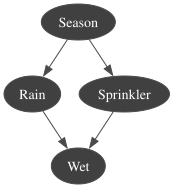

In [18]:
structure = gum.fastDAG("Season->Rain->Wet<-Sprinkler<-Season")
model = gum.BayesNet()
for n in sorted(structure.nodes()):
  model.add(structure.nameFromId(n), 2)  # binary variables
for tail, head in structure.arcs():
  model.addArc(tail, head)
model.generateCPTs()
print(model.dag() == structure)
gnb.show(model)

## Saving and loading a graph

`gg.save` and `gg.load` (or `gum.saveGraph` and `gum.loadGraph`) choose the format from the extension of the file:
`.jgum` (GUM format, JSON text), `.bgum` (GUM format, binary) or `.pkl` (pickle). Every class of graph can be saved: the
loaded graph is of the same class, and its properties are checked (a cycle in a `DAG` is refused).

In [19]:
print(gum.availableGraphExts())
for graph in (pdag, mpdag, pag, mag):
  for ext in ("jgum", "bgum"):
    gg.save(graph, f"out/graph.{ext}")
    loaded = gg.load(f"out/graph.{ext}")
    print(f"{ext} {type(graph).__name__:6} -> {type(loaded).__name__:6} {loaded == graph}")

jgum|bgum|pkl
jgum PDAG   -> PDAG   True
bgum PDAG   -> PDAG   True
jgum MPDAG  -> MPDAG  True
bgum MPDAG  -> MPDAG  True
jgum PAG    -> PAG    True
bgum PAG    -> PAG    True
jgum MAG    -> MAG    True
bgum MAG    -> MAG    True


`saveGUMstring` and `gg.fromGUMString` do the same with a string. The GUM format is JSON: it gives the class, the nodes,
the names, the arcs, the edges and the marked edges of the graph.

In [20]:
s = pdag.saveGUMstring()
print(s)
print(gg.fromGUMString(s) == pdag)

try:
  gg.fromGUMString(s.replace('"PDAG"', '"DAG"'))  # the edges of a PDAG in a DAG
except gum.GumIOError as e:
  print(e)

{"type":"PDAG","GumJsonVersion":"1.1","nodes":[0,1,2,3],"names":{"0":"A","1":"B","2":"C","3":"D"},"arcs":[[0,1]],"edges":[[2,3],[1,2]],"markedEdges":[]}
True
[pyAgrum] I/O Error: GUM graph: a DAG has no edge
